# Deliverable 1  

## Task 1 - Temperature  

In this task we gather data from Frost.no by sending a request, with specified parameters,  
the pages API and a client ID. An error will print if it fails. 

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import requests

with open('met_id.txt') as f:
    client_id = f'{f.readline().strip().split(':')[1]}'

# Define endpoint and parameters
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2026-01-01',
    'timeoffsets': 'default',
    'levels': 'default',
    }
# set end date to 26-01-01 because they use open intervals, dont include last date

# Issue an HTTP GET request
r = requests.get(endpoint, parameters, auth=(client_id, ''))
# Extract JSON data
data = r.json()

# Check if the request worked, print out any errors
if r.status_code == 200:
    data = data['data']
    print('Data retrieved from frost.met.no!')
else:
    print(f'Error! Returned status code {r.status_code}')
    print(f'Message: {data['error']['message']}')
    print(f'Reason: {data['error']['reason']}')

Data retrieved from frost.met.no!


The output from the request is first used to make a summary of summary data.

In [8]:
# This will return a Dataframe with all of the observations in a table format
df = pd.json_normalize(
    data,
    record_path='observations',
    meta=['referenceTime', 'sourceId'],
)

# New dataframe for date and temperature
temperature_df = df[['referenceTime', 'value']].copy()

temperature_df = temperature_df.rename(
    columns={
        'referenceTime': 'date',
        'value': 'temperature',
    }
)

temperature_df['date'] = pd.to_datetime(
    temperature_df['date']
)

temperature_df['temperature'] = pd.to_numeric(
    temperature_df['temperature']
)

# Check visually what data we have
print(temperature_df.shape)

print(temperature_df['date'].min())
print(temperature_df['date'].max())


def temperature_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Calculate summary statistics for the temperature data.

    Arguments:
    df: DataFrame containing a 'temperature' column.

    Returns:
    DataFrame containing the mean, median, minimum and maximum temperature."""
    summary = pd.DataFrame({
        'temperature': [
            df['temperature'].mean(),
            df['temperature'].median(),
            df['temperature'].min(),
            df['temperature'].max(),
        ]
    }, index=['mean', 'median', 'min', 'max'])

    return summary


summary = temperature_summary(temperature_df)

print(summary)


(365, 2)
2025-01-01 00:00:00+00:00
2025-12-31 00:00:00+00:00
        temperature
mean       7.869041
median     8.300000
min      -15.500000
max       23.700000


Then we used the request output to plot dayly temperatures for 2025.

C:\Users\Ginas\AppData\Local\Temp\ipykernel_21068\1985607685.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


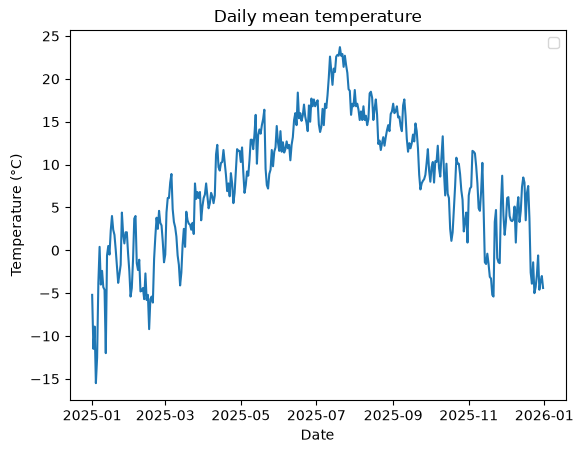

In [9]:
# lager plot
x = temperature_df['date']
y = temperature_df['temperature']

plt.plot(x, y)
plt.xlabel('Date')
plt.ylabel('Temperature (°C)')
plt.title('Daily mean temperature')
plt.legend()
plt.show()

## Task 2 - Precipitation
In this task we use the same code format to gather both dayly temperature and dayly precipitation for 2025.

This function gathers data of a variable element, still for the same time period as before (2025).

In [10]:
def get_frost_data(desired_element: str) -> pd.DataFrame:

    """Creates dataframe containing observations (value, moh, unit MM.), referenceTime and sourceId, 
    from website frost.no, at site SN17850 (Ås).

    Arguments:
        desired_element: weather element from element list at frost.no

    Returns:
        dataframe: observations for each day in timeseries.

    """ 

    with open('met_id.txt') as f:
        client_id = f.readline().strip().split(':')[1]

    # Define endpoint and parameters
        endpoint = 'https://frost.met.no/observations/v0.jsonld'
        parameters = {
            'sources': 'SN17850',
            'elements': desired_element,
            'referencetime': '2025-01-01/2026-01-01',
            'timeoffsets': 'default',
            'levels': 'default',
            }
        # set end date to 26-01-01 because they use open intervals, dont include last date
    
        # Issue an HTTP GET request, r is in JSON format
        r = requests.get(endpoint, parameters, auth=(client_id, ''))
        # Extract JSON data, make this a Python dictionary
        data = r.json()
        #print(json.dumps(data, indent=4))
    
        # Check if the request worked, print out any errors
        if r.status_code == 200:
            data = data['data']
            print('Data retrieved from frost.met.no!')
        else:
            print('Error! Returned status code %s' % r.status_code)
            print('Message: %s' % data['error']['message'])
            print('Reason: %s' % data['error']['reason'])
    
        # not all elements in data has observations, need to check for that before creating the dataframe
        # creates dataframe with observations (value, moh, unit MM.), referenceTime and sourceId
        for item in data:
            if 'observations' in item:
                dataframe = pd.json_normalize(data, record_path='observations', meta=['referenceTime', 'sourceId'],)

    return dataframe 


We then use two different functions for making easier managable tables for temperature data and precipitation data. (This should have been written as one function, taking element as variable, which then would decide column names).

In [11]:
def get_temperature_data(df: pd.DataFrame) -> pd.DataFrame:

    """Creates dataframes containing only date and temperature, from a dataframe of meteorological data.

    Arguments:
        df: a dataframe with columns 'observations', 'referenceTime' and 'sourceId' 

    Returns:
        df: a dataframe containing date and temperature

    """

    # Lager en ny dataframe for dato og temperatur
    temperature_df = df[['referenceTime', 'value']].copy()

    temperature_df = temperature_df.rename(
        columns={
            'referenceTime': 'date',
            'value': 'temperature',
        }
    )
    temperature_df['date'] = pd.to_datetime(temperature_df['date'])
    temperature_df['temperature'] = pd.to_numeric(temperature_df['temperature'])

    return temperature_df


def get_precipitation_data(df: pd.DataFrame) -> pd.DataFrame:

    """Creates dataframes containing only date and precipitation, from a dataframe of meteorological data.

    Arguments:
        df: a dataframe with columns 'observations', 'referenceTime' and 'sourceId'. 

    Returns:
        df: a dataframe containing date and precipitation.

    """
    # make dafaframe for date and precipitation
    precipitation_df = df[['referenceTime', 'value']].copy()

    precipitation_df = precipitation_df.rename(
        columns={
            'referenceTime': 'date',
            'value': 'precipitation',
        }
    )
    precipitation_df['date'] = pd.to_datetime(precipitation_df['date'])

    return precipitation_df

We then made a plot showing both temperatures and precipitation through 2025.

Data retrieved from frost.met.no!
Data retrieved from frost.met.no!


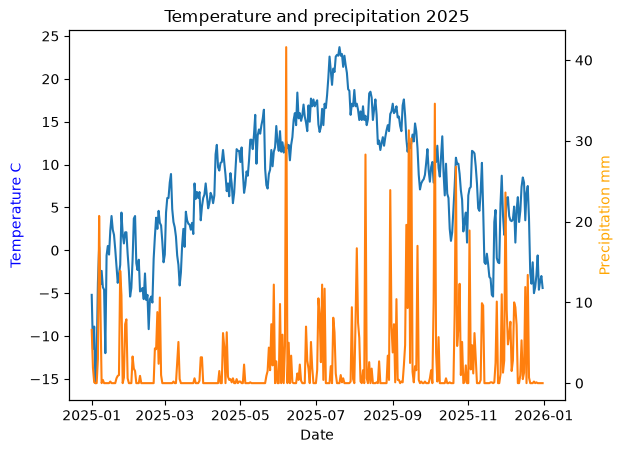

In [12]:
# gather dataframes for temperature and precepitation in simpler names
temp = get_temperature_data(get_frost_data('mean(air_temperature P1D)'))
prec = get_precipitation_data(get_frost_data('sum(precipitation_amount P1D)'))

# MAKE PLOT WITH TEMPERATURE FROM TASK 1 + PRECIPITATION
# create figure and first axis
fig1, ax1 = plt.subplots()

ax1.plot(temp['date'], temp['temperature'], color='tab:blue')
ax1.set_xlabel('Date')
ax1.set_ylabel('Temperature C', color = 'blue')

ax2 = ax1.twinx()

ax2.plot(temp['date'], prec['precipitation'], color='tab:orange')
ax2.set_xlabel('Date')
ax2.set_ylabel('Precipitation mm', color = 'orange')
plt.title('Temperature and precipitation 2025')
plt.show()


## Task 3 - Historical temperature data
In this task we have gathered the same temperature data as before (for 2025) and also temperature data from 1925, and compared them as a plot.

First we made a function for gathering the data. (We should also here have used a general function taking element and timereference as arguments, which should have been made in task 1).

In [13]:
def get_frost_data(desired_element: str, timeseries: str) -> pd.DataFrame:

    """Creates dataframe containing observations (value, moh, unit MM.), referenceTime and sourceId.

    Arguments:
        desired_element: weather element from element list at frost.no
        timeseries: formate '{start}/{end}' as 'yyyy-mm-dd/yyyy-mm-dd'

    Returns:
        dataframe: observations for each day in timeseries

    """    
    with open('met_id.txt') as f:
        client_id = f.readline().strip().split(':')[1]

    # Define endpoint and parameters
    endpoint = 'https://frost.met.no/observations/v0.jsonld'
    parameters = {
        'sources': 'SN17850',
        'elements': desired_element,
        'referencetime': timeseries,
        'timeoffsets': 'default',
        'levels': 'default',
        }
    # set end date to 26-01-01 because they use open intervals, dont include last date

    # Issue an HTTP GET request, r is in JSON format
    r = requests.get(endpoint, parameters, auth=(client_id, ''))
    # Extract JSON data, make this a Python dictionary
    data = r.json()
    #print(json.dumps(data, indent=4))

    # Check if the request worked, print out any errors
    if r.status_code == 200:
        data = data['data']
        print('Data retrieved from frost.met.no!')
    else:
        print('Error! Returned status code %s' % r.status_code)
        print('Message: %s' % data['error']['message'])
        print('Reason: %s' % data['error']['reason'])

    # not all elements in data has observations, need to check for that before creating the dataframe
    # creates dataframe with observations (value, moh, unit MM.), referenceTime and sourceId
    for item in data:
        if 'observations' in item:
            dataframe = pd.json_normalize(data, record_path='observations', meta=['referenceTime', 'sourceId'],)

    return dataframe 

Then a function for making simpler tables. 

In [14]:
def temps_for_interval(df: pd.DataFrame) -> pd.DataFrame:

    """Creates dataframes containing only date and temperature, from a dataframe of meteorological data.

    Arguments:
        df: a dataframe with columns 'observations', 'referenceTime' and 'sourceId'.

    Returns:
        df: a dataframe containing date and temperature.

    """

    temperature_df = df[['referenceTime', 'value']].copy()

    temperature_df = temperature_df.rename(
        columns={
            'referenceTime': 'date',
            'value': 'temperature',
        }
    )
    temperature_df['date'] = pd.to_datetime(temperature_df['date'])
    temperature_df['temperature'] = pd.to_numeric(temperature_df['temperature'])

    return temperature_df


The output of these functions combined are gathered in simpler variable names, and the plotted as dayly temperatures of 2025 and 1925.

Data retrieved from frost.met.no!
Data retrieved from frost.met.no!


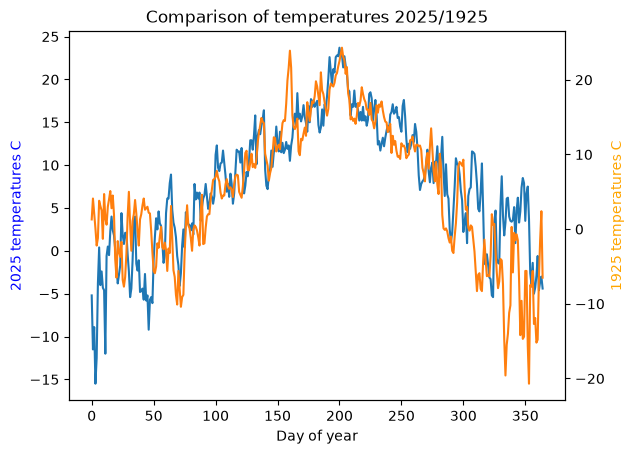

In [15]:
temps_2025 = temps_for_interval(get_frost_data('mean(air_temperature P1D)', '2025-01-01/2026-01-01'))
temps_1925 = temps_for_interval(get_frost_data('mean(air_temperature P1D)', '1925-01-01/1926-01-01'))

# make plot for comparing temperatures of 2025 and 1925.
x = range(365)
fig1, ax1 = plt.subplots()

ax1.plot(x, temps_2025['temperature'], color='tab:blue')
ax1.set_xlabel('Day of year')
ax1.set_ylabel('2025 temperatures C', color ='blue')

ax2 = ax1.twinx()

ax2.plot(x, temps_1925['temperature'], color='tab:orange')
ax2.set_xlabel('Date')
ax2.set_ylabel('1925 temperatures C', color = 'orange')

plt.title('Comparison of temperatures 2025/1925')
plt.show()
